In [13]:
import numpy as np
import hcipy as hp
import hcipy as hcipy
import matplotlib.pyplot as plt
from magaox import make_magaox_bump_mask
from apodized_mask_generator import make_magaox_piaa_lyot_stop


Define constants, 

INIT pupil and aperture for Magellan, may change to MagAO-X

Supersample the pupil by factor 8 for more detail

In [14]:
# Telescope / instrument constants
pupil_diameter = 6.5            # m
effective_focal_length = 71.5   # m

pupil_grid = hcipy.make_pupil_grid(256, diameter=pupil_diameter)

magellan_pupil_generator = make_magaox_bump_mask() #TODO: change to MagAO-X pupil when needed?
telescope_pupil = hp.evaluate_supersampled(magellan_pupil_generator, pupil_grid, 8)

hcipy.imshow_field(telescope_pupil, cmap='gray')
plt.colorbar()
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()


NameError: name 'np' is not defined

Create and select the filters: 

- Narrowband 875 filter $\lambda$ = 875nm, bandwidth = 3\%
- Broadband z' filter (here z): $\lambda$ = 908nm, bandwidth = 14\%

In [ ]:
# Define and select filter
filter_875 = {'name': '875 nm', 'wavelength': 875e-9, 'bandwidth': 0.03}
filter_z   = {'name': 'z band', 'wavelength': 908e-9, 'bandwidth': 0.13/0.908}

# filter = filter_875
filter = filter_z
wavelength = filter['wavelength']
bandwidth = filter['bandwidth']


Propagate a Monochomatic (at central wavelength of the filter) wavefront towards the focal plane.

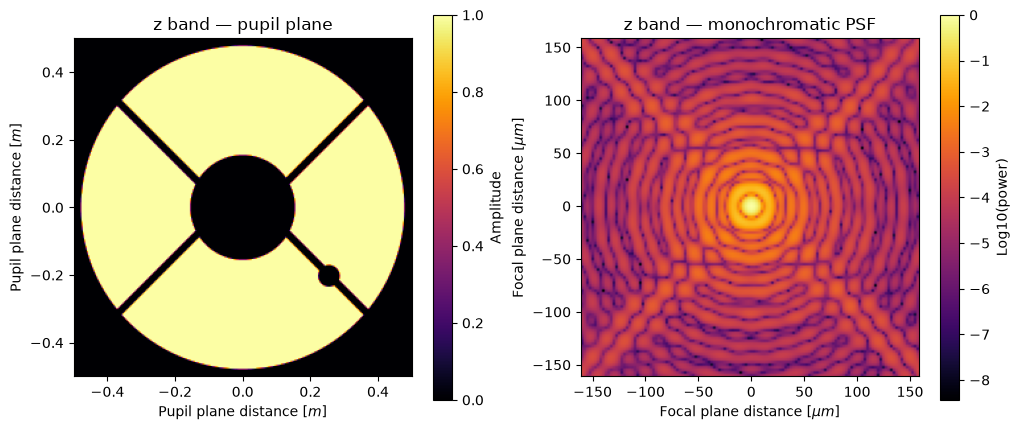

In [ ]:
wavefront = hcipy.Wavefront(telescope_pupil, wavelength=wavelength) # create wavefront object

focal_grid = hcipy.make_focal_grid(q=4, num_airy=16, pupil_diameter=pupil_diameter,
                                    focal_length=effective_focal_length, reference_wavelength=wavelength)

fraun = hcipy.FraunhoferPropagator(pupil_grid, focal_grid, focal_length=effective_focal_length)

focal_image = fraun.forward(wavefront) #plot the monochromatic PSF

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].set_title('Pupil Plane')
ax[1].set_title('Focal Plane')

hcipy.imshow_field(wavefront.amplitude, grid_units = pupil_diameter, ax=ax[0], cmap='inferno')
ax[0].set_xlabel(r'Pupil plane distance [$m$]')
ax[0].set_ylabel(r'Pupil plane distance [$m$]')
ax[0].set_title(filter['name'] + ' — pupil plane')
ax[0].set_aspect('equal')
plt.colorbar(ax[0].images[0], ax=ax[0], label='Amplitude')

hcipy.imshow_field(np.log10(focal_image.intensity / focal_image.intensity.max()), grid_units=1e-6, ax=ax[1],cmap='inferno')
ax[1].set_xlabel(r'Focal plane distance [$\mu m$]')
ax[1].set_ylabel(r'Focal plane distance [$\mu m$]')
ax[1].set_title(filter['name'] + ' — monochromatic PSF')
ax[1].set_aspect('equal')

plt.colorbar(ax[1].images[0], ax=ax[1], label='Log10(power)')
plt.show()


Add the filter bandwidth to the wavefront before propagating.

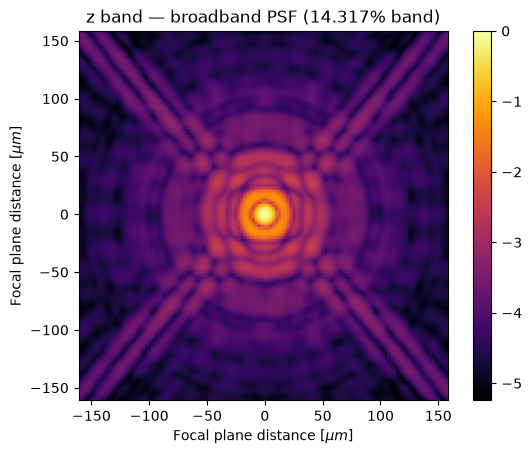

In [ ]:
focal_total = 0
for wlen in wavelength * np.linspace(1 - bandwidth / 2., 1 + bandwidth / 2., 11):
    wavefront = hcipy.Wavefront(telescope_pupil, wlen)
    focal_total += fraun.forward(wavefront).power

hcipy.imshow_field(np.log10(focal_total / focal_total.max()), grid_units=1e-6, cmap='inferno')

plt.colorbar()
plt.xlabel(r'Focal plane distance [$\mu m$]')
plt.ylabel(r'Focal plane distance [$\mu m$]')
plt.title(filter['name'] + ' — broadband PSF ({:.2f}% band)'.format(bandwidth * 100))
plt.show()


# TODO:  Finish Tutorials, simulate the fPIAA and iPIAA lenses


In [ ]:
# TODO: load CSV, make PIAA surfaces, propagate through PIAA, and plot the apodized PSF

self.pupil_diameter=8.6e-3 #m

        if self.method=='PIAA':
            radial_d0=self.piaa0_csv['Radial distance (m)'].values
            radial_d1=self.piaa1_csv['Radial distance (m)'].values
            profile0=-self.piaa0_csv['Cut depth (m)'].values #surface profile is negative of cut depth
            profile1=-self.piaa1_csv['Cut depth (m)'].values
            ###
            min_0=np.min(radial_d0)
            min_1=np.min(radial_d1)
            profile0=profile0-min_0
            profile1=profile1-min_1
            ###

            ref_ind_lenses=get_refractive_index('CAF2')
            d_pupil_piaa0=37.2e-3 #m by design (ideal)
            d_piaa0_piaa1=60.2e-3 #m by design (ideal)
            prop_pupil_piaa0=FresnelPropagator(self.aperture.grid,d_pupil_piaa0) #AngularSpectrumPropagator
            prop_piaa0_piaa1=FresnelPropagator(self.aperture.grid,d_piaa0_piaa1)
            prop_piaa1_pupil=FresnelPropagator(self.aperture.grid,d_piaa0_piaa1+d_pupil_piaa0)

            prop_LS_piaa1=FresnelPropagator(self.aperture.grid,d_pupil_piaa0)
            prop_piaa1_piaa0=FresnelPropagator(self.aperture.grid,d_piaa0_piaa1)
            prop_piaa0_LS=FresnelPropagator(self.aperture.grid,d_piaa0_piaa1+d_pupil_piaa0)

            self.prop_pupil_piaa0=prop_pupil_piaa0
            self.prop_piaa0_piaa1=prop_piaa0_piaa1
            self.prop_piaa1_pupil=prop_piaa1_pupil
            self.prop_LS_piaa1=prop_LS_piaa1
            self.prop_piaa1_piaa0=prop_piaa1_piaa0
            self.prop_piaa0_LS=prop_piaa0_LS

            sag0=Field(np.interp(self.aperture.grid.as_('polar').r,radial_d0,-profile0),self.aperture.grid)
            sag1=Field(np.interp(self.aperture.grid.as_('polar').r,radial_d1,-profile1),self.aperture.grid)

            piaa0 = SurfaceApodizer(-sag0, ref_ind_lenses)
            piaa1 = SurfaceApodizer(-sag1, ref_ind_lenses)
            self.piaa0=piaa0
            self.piaa1=piaa1


# APODIZE WITH PIAA

apodized_wf_dict={}
        # apodized_wfs=[]
        current_wf=Wavefront(self.aperture*np.exp(2j*np.pi*self.separation*self.aperture.grid.x/self.pupil_diameter))
        index=-1
        for wl in self.wavelengths:
            index+=1
            current_wf.wavelength=wl
            current_wf.total_power=1
            wf_piaa0 = self.piaa0.forward(self.prop_pupil_piaa0.forward(current_wf))
            wf_piaa1 = self.piaa1.forward(self.prop_piaa0_piaa1.forward(wf_piaa0))
            apodized_wf_at_pupil = self.prop_piaa1_pupil.backward(wf_piaa1)
            # apodized_wf_at_pupil.total_power=1
            apodized_wf_dict[index]=apodized_wf_at_pupil
            # apodized_wfs[index]=apodized_wf_at_pupil
        return apodized_wf_dict

# TODO: Define the focal plane mask and propagate the apodized wavefront through it to get the final PSF. Then plot the final PSF.  

n_rings=10
wl=0.908e-6
F_number=69
SR=wl*F_number
expected_max_radius_norm=0.75
expected_heights=np.array([1.26196831, 0.94074998, 0.77836148, 0.6366583 , 0.7739299 , 3.19782967, 0.85539274, 0.79005693, 0.88346143, 0.87813155]) #microns

# TODO: use inverse PIAA to get final PSF and plot it.


IndentationError: unexpected indent (3245088744.py, line 5)